# Capstone Project: SMS Spam Detection with TF-IDF and Naive Bayes
**Author:** Maryam ([GitHub: Maryamahsan78](https://github.com/Maryamahsan78)) | ML Internship, Week 4

**Pipeline of this notebook:** 1. Problem  2. Data and EDA  3. Preprocessing and TF-IDF  4. Modelling and tuning  5. Final evaluation on the locked test set  6. Explaining the model  7. Demo  8. Conclusions and limitations

# 1. Problem understanding

## 1. Problem statement
- **Task:** binary text classification. Input = the text of one SMS, output = `spam` or `ham`.
- **Who uses it:** a phone or messaging app that filters unwanted messages.
- **Which mistake is worse?** Marking a real message as spam (**false positive**) can hide something important, so we care about **precision on spam**. Letting a spam through (**false negative**) is annoying but less harmful. We will report precision, recall and F1, not just accuracy.
- **Why not accuracy alone:** if most messages are ham, a model that always says "ham" already gets a high accuracy (we will check how high below).

# 2. Data and exploratory analysis

In [1]:
%%writefile spam_utils.py
import re

def clean_text(s):
    s = s.lower()
    s = re.sub(r'(https?://\S+|www\.\S+)', ' urltoken ', s)
    s = re.sub(r'[£$€]\s?\d[\d,.]*|\d[\d,.]*\s?(?:p|pounds|usd)\b', ' moneytoken ', s)
    s = re.sub(r'\d[\d\- ]{4,}\d|\d+', ' numtoken ', s)
    s = re.sub(r'[^a-z\s]', ' ', s)
    return re.sub(r'\s+', ' ', s).strip()

Writing spam_utils.py


The cleaning function lives in its own file, `spam_utils.py`, so that the saved model and the demo app can import it. It is explained in section 3.

In [2]:
import numpy as np, pandas as pd, re, time, sys, joblib
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report, make_scorer, precision_score,
                             recall_score, f1_score, accuracy_score)
from spam_utils import clean_text
sns.set_theme(style='whitegrid')

URL = 'https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv'   # SMS Spam Collection
df = pd.read_csv(URL, sep='\t', header=None, names=['label', 'message'])
print(df.shape); df.head()

(5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


**Source:** the SMS Spam Collection (UCI Machine Learning Repository), a public set of labelled English SMS messages. If the link ever fails, download it from UCI or Kaggle and use `pd.read_csv(..., encoding='latin-1')` with the `v1`/`v2` columns renamed to `label`/`message`.

In [3]:
df.info()
print('Missing values:\n', df.isna().sum())
print('Duplicate messages:', df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
Missing values:
 label      0
message    0
dtype: int64
Duplicate messages: 403


## 3. Class balance
Is the data balanced? This decides which metric we trust.

label
ham     4825
spam     747
Name: count, dtype: int64
label
ham     0.866
spam    0.134
Name: count, dtype: float64

Accuracy of a model that ALWAYS says ham: 0.866


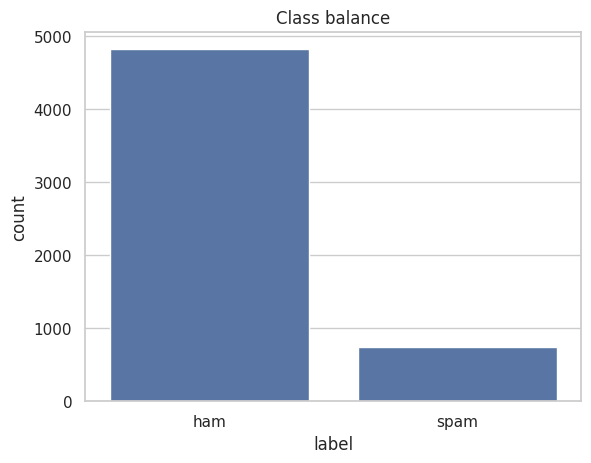

In [4]:
counts = df['label'].value_counts()
print(counts); print((counts / len(df)).round(3))
print('\nAccuracy of a model that ALWAYS says ham:', round(counts['ham'] / len(df), 3))
sns.countplot(data=df, x='label', order=['ham', 'spam']); plt.title('Class balance'); plt.show()

**Write below what you see:** the data is imbalanced (about 87% ham, 13% spam), so a model that never flags spam already scores about 0.87 accuracy. That is why accuracy alone is misleading and we use precision, recall and F1 for the spam class.

## 4. Look at real examples

In [5]:
pd.set_option('display.max_colwidth', 200)
print('--- 5 spam ---'); display(df[df.label == 'spam'].sample(5, random_state=1))
print('--- 5 ham ---');  display(df[df.label == 'ham'].sample(5, random_state=1))

--- 5 spam ---


,label,message
5492,spam,Marvel Mobile Play the official Ultimate Spider-man game (£4.50) on ur mobile right now. Text SPIDER to 83338 for the game & we ll send u a FREE 8Ball wallpaper
1146,spam,"Thank you, winner notified by sms. Good Luck! No future marketing reply STOP to 84122 customer services 08450542832"
1699,spam,"Free msg. Sorry, a service you ordered from 81303 could not be delivered as you do not have sufficient credit. Please top up to receive the service."
2250,spam,"Thanks for your ringtone order, ref number R836. Your mobile will be charged £4.50. Should your tone not arrive please call customer services on 09065069154"
5028,spam,PRIVATE! Your 2003 Account Statement for shows 800 un-redeemed S.I.M. points. Call 08715203685 Identifier Code:4xx26 Expires 13/10/04


--- 5 ham ---


,label,message
2535,ham,Ok enjoy . R u there in home.
1213,ham,"Yo, the game almost over? Want to go to walmart soon"
522,ham,Shall i come to get pickle
5398,ham,Hi. Hope you had a good day. Have a better night.
700,ham,K..u also dont msg or reply to his msg..


## 5. Simple features: do they separate the classes?
Before any TF-IDF, check a few hand-made features: message length, number of digits, number of capital letters, and whether the message has a `£`/`$` sign or `!`.

In [6]:
df['n_chars']  = df['message'].str.len()
df['n_words']  = df['message'].str.split().str.len()
df['n_digits'] = df['message'].str.count(r'\d')
df['n_upper']  = df['message'].str.count(r'[A-Z]')
df['has_money'] = df['message'].str.contains(r'[£$€]').astype(int)
df['has_excl']  = df['message'].str.contains('!').astype(int)
df.groupby('label')[['n_chars', 'n_words', 'n_digits', 'n_upper', 'has_money', 'has_excl']].mean().round(2)

,n_chars,n_words,n_digits,n_upper,has_money,has_excl
label,,,,,,
ham,71.48,14.31,0.31,4.10,0.00,0.12
spam,138.67,23.91,15.81,15.47,0.34,0.49


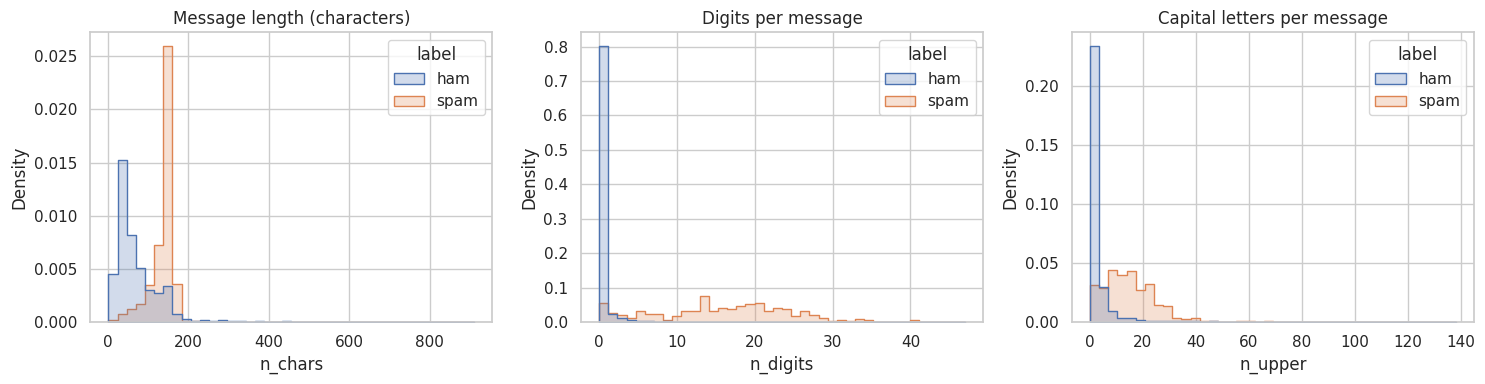

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col, t in zip(ax, ['n_chars', 'n_digits', 'n_upper'], ['Message length (characters)', 'Digits per message', 'Capital letters per message']):
    sns.histplot(data=df, x=col, hue='label', bins=40, stat='density', common_norm=False, ax=a, element='step'); a.set_title(t)
plt.tight_layout(); plt.show()

**Write below what you see:** spam messages are longer, contain many more digits (phone numbers, prizes) and more capital letters than ham.

## 6. Most common words in each class
Count words with `CountVectorizer` (English stop words removed), separately for spam and ham.

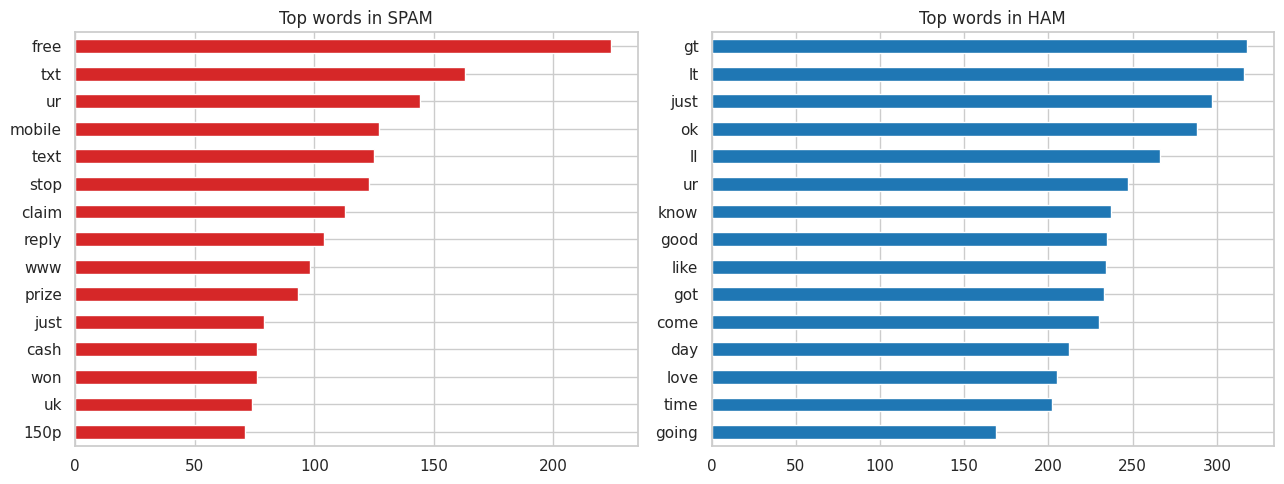

In [8]:
def top_words(texts, n=15):
    cv = CountVectorizer(stop_words='english', lowercase=True)
    X = cv.fit_transform(texts)
    freq = np.asarray(X.sum(axis=0)).ravel()
    return pd.Series(freq, index=cv.get_feature_names_out()).sort_values(ascending=False).head(n)

spam_top, ham_top = top_words(df.loc[df.label == 'spam', 'message']), top_words(df.loc[df.label == 'ham', 'message'])
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
spam_top[::-1].plot.barh(ax=ax[0], color='tab:red'); ax[0].set_title('Top words in SPAM')
ham_top[::-1].plot.barh(ax=ax[1], color='tab:blue'); ax[1].set_title('Top words in HAM')
plt.tight_layout(); plt.show()

**Write below what you see:** spam is full of call-to-action and prize words (`free`, `txt`, `mobile`, `claim`, `reply`, `prize`, `cash`), while ham looks like ordinary chat. This is exactly the kind of signal that TF-IDF and Naive Bayes can learn from.

# 3. Preprocessing

## 3.1 Remove duplicates and encode labels

In [9]:
print('Before:', df.shape)
df = df.drop_duplicates(subset='message').reset_index(drop=True)
print('After removing duplicate messages:', df.shape)
df['y'] = (df['label'] == 'spam').astype(int)      # spam = 1 (the class we care about), ham = 0
print('Spam share:', round(df['y'].mean(), 3))

Before: (5572, 8)
After removing duplicate messages: (5169, 8)
Spam share: 0.126


**Why remove duplicates?** If the same message is in both train and test, the model is graded on something it has already seen (leakage), so the score looks better than it really is. We keep spam as class `1`, so precision and recall later are about spam.

## 3.2 Train/test split (before anything is fitted)

## 2. Train/test split (before anything is fitted)
`stratify=y` keeps the same spam share in both parts. From now on the **test set is locked away** until Thursday. Every step that learns something from data (TF-IDF vocabulary, scaling, tuning) uses only the training part.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(df['message'], df['y'], test_size=0.2, random_state=42, stratify=df['y'])
print('Train:', len(X_train), ' Test:', len(X_test))
print('Spam share  train:', round(y_train.mean(), 3), ' test:', round(y_test.mean(), 3))

Train: 4135  Test: 1034
Spam share  train: 0.126  test: 0.127


## 3. Text cleaning
Rules we apply (and why):
- **Lowercase**, so `FREE` and `free` are the same word.
- Replace **URLs, phone numbers and other digit strings** by one token each (`urltoken`, `numtoken`), because the exact number does not matter, but *having* a number is a strong spam signal (we saw this on Monday).
- Replace **money symbols** by `moneytoken`.
- Remove other punctuation.

Stop words and n-grams are handled by the vectorizer in step 5.

In [11]:
examples = X_train[y_train == 1].head(3).tolist() + X_train[y_train == 0].head(2).tolist()
for e in examples:
    print('BEFORE:', e); print('AFTER :', clean_text(e)); print()
X_train_clean = X_train.apply(clean_text)
X_test_clean  = X_test.apply(clean_text)

BEFORE: 18 days to Euro2004 kickoff! U will be kept informed of all the latest news and results daily. Unsubscribe send GET EURO STOP to 83222.
AFTER : numtoken days to euro numtoken kickoff u will be kept informed of all the latest news and results daily unsubscribe send get euro stop to numtoken

BEFORE: You will be receiving this week's Triple Echo ringtone shortly. Enjoy it!
AFTER : you will be receiving this week s triple echo ringtone shortly enjoy it

BEFORE: Dont forget you can place as many FREE Requests with 1stchoice.co.uk as you wish. For more Information call 08707808226.
AFTER : dont forget you can place as many free requests with numtoken stchoice co uk as you wish for more information call numtoken

BEFORE: Ta-Daaaaa! I am home babe, are you still up ?
AFTER : ta daaaaa i am home babe are you still up

BEFORE: Yup having my lunch buffet now.. U eat already?
AFTER : yup having my lunch buffet now u eat already



## 3.3 TF-IDF

## 4. What is TF-IDF? (tiny example first)
- **TF (term frequency):** how often a word appears in *this* message.
- **IDF (inverse document frequency):** how *rare* the word is across all messages. Common words (`the`, `you`) get a low IDF, rare and specific words (`prize`) get a high one.
- **TF-IDF = TF x IDF.** A word is important for a message if it is frequent there but rare elsewhere. Each message is then scaled to length 1 (L2 norm), so long and short messages are comparable.

In [12]:
toy = ['free prize call now', 'call me later', 'free entry call now now']
tv = TfidfVectorizer()
M = tv.fit_transform(toy)
pd.DataFrame(M.toarray(), columns=tv.get_feature_names_out(), index=toy).round(2)

,call,entry,free,later,me,now,prize
free prize call now,0.37,0.00,0.48,0.00,0.00,0.48,0.63
call me later,0.39,0.00,0.00,0.65,0.65,0.00,0.00
free entry call now now,0.29,0.49,0.37,0.00,0.00,0.74,0.00


`call` appears in all 3 messages, so it gets a low weight. `prize` and `later` appear once, so they get higher weights. `now` is repeated in the third message, which raises its TF there.

## 5. Fit TF-IDF on the training set only
`fit` learns the **vocabulary and the IDF values**, so it must see only training data. Then `transform` is applied to both sets. Fitting on all data would leak information from the test set.

Settings: `stop_words='english'` (drop very common words), `ngram_range=(1, 2)` (single words and word pairs such as `free entry`), `min_df=2` (ignore words that appear in fewer than 2 training messages).

In [13]:
tfidf = TfidfVectorizer(stop_words='english', ngram_range=(1, 2), min_df=2)
Xtr = tfidf.fit_transform(X_train_clean)     # fit + transform on TRAIN
Xte = tfidf.transform(X_test_clean)          # transform only on TEST
print('Train matrix:', Xtr.shape, '| Test matrix:', Xte.shape)
print('Vocabulary size:', len(tfidf.vocabulary_))
print('Share of zeros (sparsity):', round(1 - Xtr.nnz / (Xtr.shape[0] * Xtr.shape[1]), 4))

Train matrix: (4135, 5700) | Test matrix: (1034, 5700)
Vocabulary size: 5700
Share of zeros (sparsity): 0.9984


Each message becomes a long vector with one number per word. Almost all entries are zero (a message uses only a few words), which is why scikit-learn stores it as a **sparse** matrix.

In [14]:
terms = np.array(tfidf.get_feature_names_out())
idf = pd.Series(tfidf.idf_, index=terms)
print('Lowest IDF (most common words):', idf.sort_values().head(10).index.tolist())
print('Highest IDF (rarest words)    :', idf.sort_values().tail(5).index.tolist())

def top_terms(i, n=8):
    row = Xtr[i].toarray().ravel(); idx = row.argsort()[::-1][:n]
    return {terms[j]: round(float(row[j]), 2) for j in idx if row[j] > 0}
i_spam = int(np.where(y_train.values == 1)[0][0]); i_ham = int(np.where(y_train.values == 0)[0][0])
print('\nHighest TF-IDF terms in a SPAM message:', top_terms(i_spam))
print('Highest TF-IDF terms in a HAM message :', top_terms(i_ham))

Lowest IDF (most common words): ['numtoken', 'moneytoken', 'just', 'numtoken numtoken', 'ur', 'ok', 'know', 'gt', 'lt', 'll']
Highest IDF (rarest words)    : ['intelligent', 'zed numtoken', 'zoe', 'yup having', 'yup ok']

Highest TF-IDF terms in a SPAM message: {'euro': 0.47, 'news results': 0.25, 'latest news': 0.25, 'results daily': 0.25, 'euro numtoken': 0.24, 'daily': 0.24, 'results': 0.24, 'informed': 0.23}
Highest TF-IDF terms in a HAM message : {'home babe': 0.63, 'ta': 0.57, 'babe': 0.4, 'home': 0.35}


## 6. How do the settings change the vocabulary?
Fit on the training set with different settings and compare the vocabulary size.

In [15]:
rows = []
for name, kw in {'unigrams, no min_df': dict(ngram_range=(1, 1)), 'unigrams, min_df=2': dict(ngram_range=(1, 1), min_df=2),
                 '1-2 grams, min_df=2': dict(ngram_range=(1, 2), min_df=2), '1-2 grams, no min_df': dict(ngram_range=(1, 2))}.items():
    rows.append((name, len(TfidfVectorizer(stop_words='english', **kw).fit(X_train_clean).vocabulary_)))
pd.DataFrame(rows, columns=['setting', 'vocabulary size']).set_index('setting')

,vocabulary size
setting,
"unigrams, no min_df",6556
"unigrams, min_df=2",2841
"1-2 grams, min_df=2",5700
"1-2 grams, no min_df",29534


`min_df` removes words seen only once (often typos or names), which keeps the model smaller and less likely to overfit. We will tune `ngram_range` and `min_df` with cross-validation on Wednesday.

# 4. Modelling and tuning

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)   # used for every model comparison and search

## 2. Why a Pipeline?
`Pipeline([('tfidf', ...), ('model', ...)])` runs cleaning + TF-IDF + classifier as one unit. During cross-validation, TF-IDF is **refit on each training fold only**, so nothing leaks from the validation fold. It also means the saved model accepts a **raw message** and returns a prediction, which is what the demo app needs.

## 3. Baseline and a first Naive Bayes

In [17]:
def make_pipe(model, **tfidf_kw):
    return Pipeline([('tfidf', TfidfVectorizer(preprocessor=clean_text, stop_words='english', **tfidf_kw)), ('model', model)])

from sklearn.metrics import make_scorer, precision_score
scoring = {'accuracy': 'accuracy', 'precision': make_scorer(precision_score, zero_division=0), 'recall': 'recall', 'f1': 'f1'}   # all about the SPAM class (label 1)
def evaluate(pipe):
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    return {k: r['test_' + k].mean() for k in scoring}

base = evaluate(Pipeline([('tfidf', TfidfVectorizer(preprocessor=clean_text)), ('model', DummyClassifier(strategy='most_frequent'))]))
nb = evaluate(make_pipe(MultinomialNB()))
pd.DataFrame({'Dummy (always ham)': base, 'Naive Bayes (default)': nb}).T.round(3)

,accuracy,precision,recall,f1
Dummy (always ham),0.874,0.0,0.00,0.00
Naive Bayes (default),0.967,1.0,0.74,0.85


The dummy model gets high accuracy (about 0.87) but **zero** precision, recall and F1 for spam, because it never flags anything. This is why we judge by precision, recall and F1. Naive Bayes already does far better.

## 4. Compare several models (5-fold CV, default settings)
- **Multinomial Naive Bayes** and **Complement NB**: the classic text classifiers.
- **Logistic Regression** and **Linear SVM**: strong linear models for sparse text features.
- **Random Forest**: a tree ensemble, usually slower and weaker on TF-IDF text.

In [18]:
candidates = {'Multinomial NB': MultinomialNB(), 'Complement NB': ComplementNB(),
              'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
              'Linear SVM': LinearSVC(random_state=42), 'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)}
rows = {}
for name, model in candidates.items():
    t0 = time.time(); rows[name] = {**evaluate(make_pipe(model)), 'time (s)': time.time() - t0}
comp = pd.DataFrame(rows).T.round(3).sort_values('f1', ascending=False); comp

,accuracy,precision,recall,f1,time (s)
Linear SVM,0.984,0.956,0.916,0.935,1.521
Random Forest,0.981,0.989,0.856,0.918,17.112
Logistic Regression,0.967,0.945,0.787,0.859,3.717
Multinomial NB,0.967,1.000,0.740,0.850,1.897
Complement NB,0.954,0.749,0.950,0.838,2.177


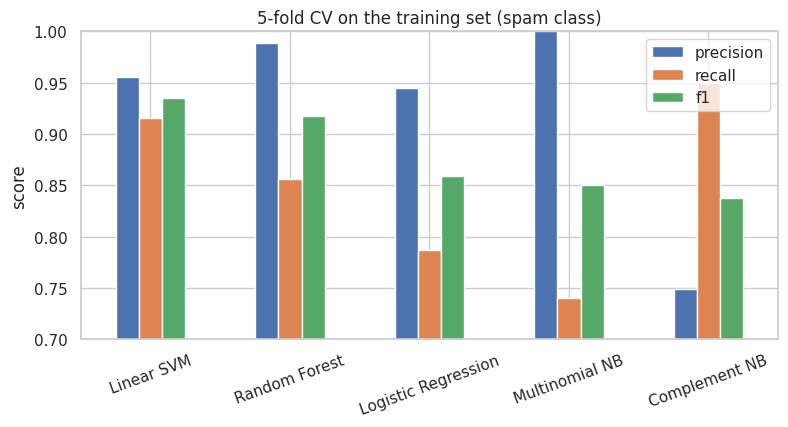

In [19]:
comp[['precision', 'recall', 'f1']].plot.bar(figsize=(9, 4), ylim=(0.7, 1.0), title='5-fold CV on the training set (spam class)')
plt.xticks(rotation=20); plt.ylabel('score'); plt.show()

**Write below what you see:** compare precision and recall. Naive Bayes usually has very high precision but can miss some spam (lower recall). Linear models tend to balance the two better.

## 5. Tune with GridSearchCV
Tune the TF-IDF settings and the model's key hyperparameter together, using **F1 for spam** as the score:
- Naive Bayes: `alpha` (smoothing: how much to trust words that were never seen in spam).
- Linear SVM: `C` (how strict the fit is).

In [20]:
tfidf_grid = {'tfidf__ngram_range': [(1, 1), (1, 2)], 'tfidf__min_df': [1, 2, 3], 'tfidf__sublinear_tf': [False, True]}
searches = {}
for name, pipe, extra in [('Naive Bayes', make_pipe(MultinomialNB()), {'model__alpha': [0.01, 0.05, 0.1, 0.5, 1.0]}),
                          ('Linear SVM', make_pipe(LinearSVC(random_state=42)), {'model__C': [0.1, 0.5, 1, 5, 10]})]:
    grid = {**tfidf_grid, **extra}
    n = int(np.prod([len(v) for v in grid.values()]))
    t0 = time.time(); g = GridSearchCV(pipe, grid, cv=cv, scoring='f1', n_jobs=-1).fit(X_train, y_train)
    searches[name] = g
    print(f'{name}: {n} combinations x 5 folds = {n*5} fits, {time.time()-t0:.0f} s')
    print('  best params:', {k: (tuple(v) if isinstance(v, tuple) else v) for k, v in g.best_params_.items()})
    print('  best CV F1 :', round(g.best_score_, 4), '\n')

Naive Bayes: 60 combinations x 5 folds = 300 fits, 75 s
  best params: {'model__alpha': 0.1, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2), 'tfidf__sublinear_tf': True}
  best CV F1 : 0.9495 

Linear SVM: 60 combinations x 5 folds = 300 fits, 65 s
  best params: {'model__C': 1, 'tfidf__min_df': 3, 'tfidf__ngram_range': (1, 2), 'tfidf__sublinear_tf': False}
  best CV F1 : 0.9521 



In [21]:
tuned = pd.DataFrame({
    'default CV F1': {'Naive Bayes': comp.loc['Multinomial NB', 'f1'], 'Linear SVM': comp.loc['Linear SVM', 'f1']},
    'tuned CV F1 (best_score_)': {k: v.best_score_ for k, v in searches.items()}}).round(4)
tuned['gain'] = (tuned['tuned CV F1 (best_score_)'] - tuned['default CV F1']).round(4); tuned

,default CV F1,tuned CV F1 (best_score_),gain
Naive Bayes,0.850,0.9495,0.0995
Linear SVM,0.935,0.9521,0.0171


**Read this honestly:** `best_score_` is picked as the best of many tries on the same folds, so it is slightly optimistic, and a gain of 0.002 or 0.005 is within the fold-to-fold noise. Check the spread too:

In [22]:
for k, g in searches.items():
    r = pd.DataFrame(g.cv_results_).sort_values('rank_test_score').iloc[0]
    print(f'{k}: best CV F1 = {r.mean_test_score:.4f} +/- {r.std_test_score:.4f} (std across 5 folds)')
print()
r = pd.DataFrame(searches['Naive Bayes'].cv_results_)
print('Naive Bayes: F1 range over all 60 settings =', round(r.mean_test_score.min(), 3), 'to', round(r.mean_test_score.max(), 3))

Naive Bayes: best CV F1 = 0.9495 +/- 0.0081 (std across 5 folds)
Linear SVM: best CV F1 = 0.9521 +/- 0.0069 (std across 5 folds)

Naive Bayes: F1 range over all 60 settings = 0.813 to 0.95


## 6. Choose the final model
We use **Naive Bayes** as the main model (it is the project's chosen method, simple, fast and easy to explain) and keep the tuned **Linear SVM** as a comparison. If the SVM is clearly better by more than the noise, mention it in your report.

Where does the tuned Naive Bayes make mistakes on the training data? Use `cross_val_predict` so each prediction comes from a model that did not see that message:

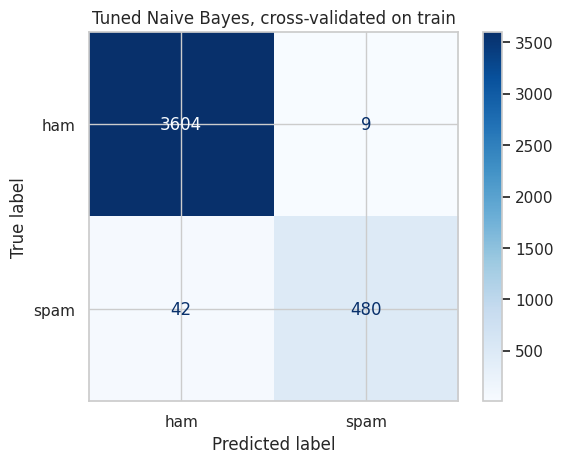

              precision    recall  f1-score   support

         ham       0.99      1.00      0.99      3613
        spam       0.98      0.92      0.95       522

    accuracy                           0.99      4135
   macro avg       0.99      0.96      0.97      4135
weighted avg       0.99      0.99      0.99      4135



In [23]:
best = searches['Naive Bayes'].best_estimator_
pred = cross_val_predict(best, X_train, y_train, cv=cv)
ConfusionMatrixDisplay.from_predictions(y_train, pred, display_labels=['ham', 'spam'], cmap='Blues'); plt.title('Tuned Naive Bayes, cross-validated on train'); plt.show()
print(classification_report(y_train, pred, target_names=['ham', 'spam']))

In [24]:
errors = pd.DataFrame({'message': X_train.values, 'true': y_train.values, 'pred': pred})
pd.set_option('display.max_colwidth', 160)
print('Spam that slipped through (false negatives):'); display(errors[(errors.true == 1) & (errors.pred == 0)].head(5))
print('Ham wrongly flagged as spam (false positives):'); display(errors[(errors.true == 0) & (errors.pred == 1)].head(5))

Spam that slipped through (false negatives):


,message,true,pred
30,Dont forget you can place as many FREE Requests with 1stchoice.co.uk as you wish. For more Information call 08707808226.,1,0
94,You won't believe it but it's true. It's Incredible Txts! Reply G now to learn truly amazing things that will blow your mind. From O2FWD only 18p/txt,1,0
218,Guess who am I?This is the first time I created a web page WWW.ASJESUS.COM read all I wrote. I'm waiting for your opinions. I want to be your friend 1/1,1,0
268,"Oh my god! I've found your number again! I'm so glad, text me back xafter this msgs cst std ntwk chg £1.50",1,0
292,Hi I'm sue. I am 20 years old and work as a lapdancer. I love sex. Text me live - I'm i my bedroom now. text SUE to 89555. By TextOperator G2 1DA 150ppmsg 18+,1,0


Ham wrongly flagged as spam (false positives):


,message,true,pred
109,Yavnt tried yet and never played original either,0,1
115,Package all your programs well,0,1
396,I liked the new mobile,0,1
1643,Wewa is 130. Iriver 255. All 128 mb.,0,1
2138,Dhoni have luck to win some big title.so we will win:),0,1


Look at these messages: why might the model have missed them? (For example, a spam message that has no typical spam words, or a normal message that contains `free` or a number.)

# 5. Final evaluation on the locked test set

The test set has not been used for any decision so far (cleaning rules, TF-IDF settings, model choice and hyperparameters all came from the training data). We evaluate **once**. If we changed the model after seeing these numbers, the test set would no longer be an honest estimate.

accuracy            0.988
precision (spam)    0.976
recall (spam)       0.931
F1 (spam)           0.953

Cross-validated F1 on train was 0.950, test F1 is 0.953


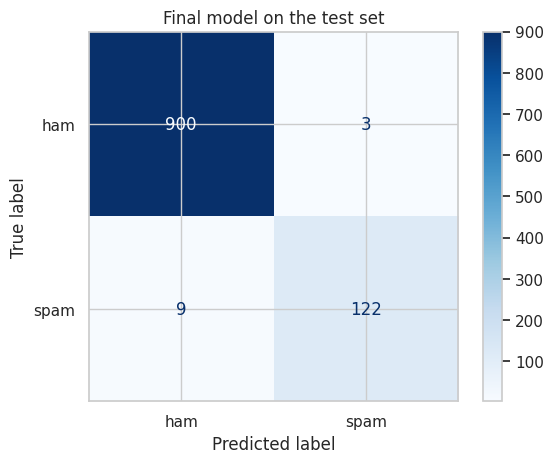

              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       903
        spam       0.98      0.93      0.95       131

    accuracy                           0.99      1034
   macro avg       0.98      0.96      0.97      1034
weighted avg       0.99      0.99      0.99      1034



In [25]:
final = searches['Naive Bayes'].best_estimator_          # already refit on the full training set by GridSearchCV
pred = final.predict(X_test)
res = pd.Series({'accuracy': accuracy_score(y_test, pred), 'precision (spam)': precision_score(y_test, pred),
                 'recall (spam)': recall_score(y_test, pred), 'F1 (spam)': f1_score(y_test, pred)}).round(3)
print(res.to_string())
print(f"\nCross-validated F1 on train was {searches['Naive Bayes'].best_score_:.3f}, test F1 is {res['F1 (spam)']:.3f}")
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['ham', 'spam'], cmap='Blues'); plt.title('Final model on the test set'); plt.show()
print(classification_report(y_test, pred, target_names=['ham', 'spam']))

**How sure can we be?** The test set has about 130 spam messages, so each missed spam changes recall by about 0.8 percentage points. A bootstrap (resampling the test messages with replacement) shows a plausible range for F1.

In [26]:
rng = np.random.RandomState(0); yt = y_test.values; boot = []
for _ in range(1000):
    idx = rng.randint(0, len(yt), len(yt)); boot.append(f1_score(yt[idx], pred[idx]))
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f'Test F1 = {f1_score(yt, pred):.3f}, 95% bootstrap interval: {lo:.3f} to {hi:.3f}')

Test F1 = 0.953, 95% bootstrap interval: 0.925 to 0.976


**Compare with the other candidates (for the report only, the choice was already made):**

In [27]:
svm_test = f1_score(y_test, searches['Linear SVM'].best_estimator_.predict(X_test))
dummy_test = f1_score(y_test, DummyClassifier(strategy='most_frequent').fit(X_train, y_train).predict(X_test), zero_division=0)
print(f'Test F1: Naive Bayes {f1_score(y_test, pred):.3f} | Linear SVM {svm_test:.3f} | always-ham baseline {dummy_test:.3f}')

Test F1: Naive Bayes 0.953 | Linear SVM 0.941 | always-ham baseline 0.000


In [28]:
pd.set_option('display.max_colwidth', 160)
err = pd.DataFrame({'message': X_test.values, 'true': y_test.values, 'pred': pred})
print('Spam that slipped through (false negatives):'); display(err[(err.true == 1) & (err.pred == 0)])
print('Ham wrongly flagged as spam (false positives):'); display(err[(err.true == 0) & (err.pred == 1)])

Spam that slipped through (false negatives):


,message,true,pred
79,Thanks for the Vote. Now sing along with the stars with Karaoke on your mobile. For a FREE link just reply with SING now.,1,0
326,Missed call alert. These numbers called but left no message. 07008009200,1,0
329,"SMS. ac sun0819 posts HELLO:""You seem cool, wanted to say hi. HI!!!"" Stop? Send STOP to 62468",1,0
437,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about we go slo n hard! Txt XXX SLO(4msgs),1,0
456,Check Out Choose Your Babe Videos @ sms.shsex.netUN fgkslpoPW fgkslpo,1,0
486,"In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Day, C-Red Day. (Send A, B or C)",1,0
544,"Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am till 8pm, and on Thurs, Fri & Sat night this week. They're selling fast!",1,0
690,"Latest News! Police station toilet stolen, cops have nothing to go on!",1,0
992,Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Sept and go Large or Super with Coca-Cola and walk out a winner,1,0


Ham wrongly flagged as spam (false positives):


,message,true,pred
28,Then why you not responding,0,1
327,K k:) sms chat with me.,0,1
469,K:)eng rocking in ashes:),0,1


**Write below:** what do the mistakes have in common? A false positive (a real message blocked) is the costlier mistake for this project, so how many are there, and is that acceptable?

# 6. Explaining the model

Naive Bayes learns, for each word, how much more likely it is in spam than in ham. The words with the largest difference are the model's strongest spam and ham signals.

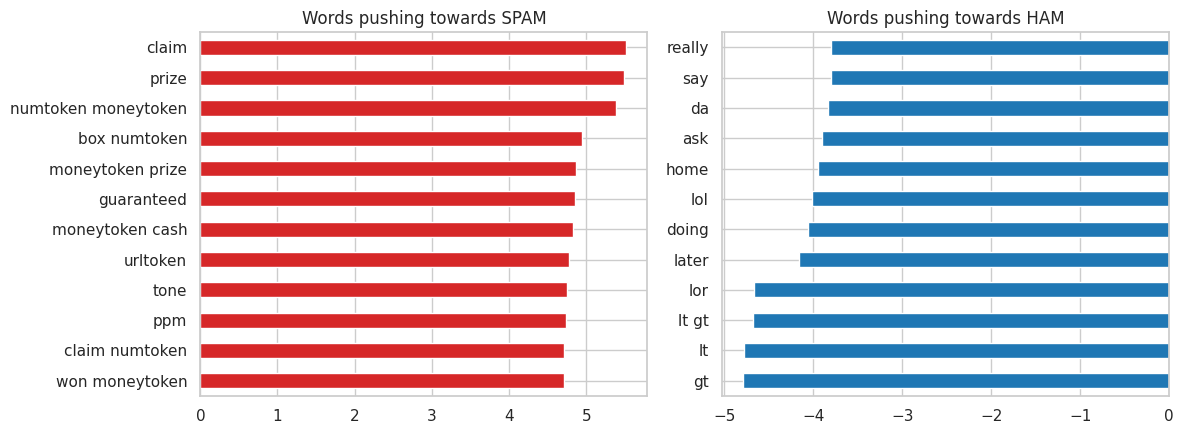

In [29]:
nbm = final.named_steps['model']; terms = np.array(final.named_steps['tfidf'].get_feature_names_out())
log_ratio = nbm.feature_log_prob_[1] - nbm.feature_log_prob_[0]          # class 1 = spam
order = log_ratio.argsort()
top = pd.concat([pd.Series(log_ratio[order[-12:]][::-1], index=terms[order[-12:]][::-1]).rename('spam signals'),
                 pd.Series(log_ratio[order[:12]], index=terms[order[:12]]).rename('ham signals')], axis=1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
top['spam signals'].dropna()[::-1].plot.barh(ax=ax[0], color='tab:red', title='Words pushing towards SPAM')
top['ham signals'].dropna().plot.barh(ax=ax[1], color='tab:blue', title='Words pushing towards HAM')
plt.tight_layout(); plt.show()

# 7. Save the model and demo

In [30]:
joblib.dump(final, 'spam_model.joblib')
loaded = joblib.load('spam_model.joblib')
def predict_message(msg):
    p = float(loaded.predict_proba([msg])[0, 1])
    return {'spam': p, 'ham': 1 - p}
for msg in ['WINNER!! You have won a 1000 pound prize. Call 09061701461 now to claim', 'Hey, are we still meeting for lunch tomorrow?']:
    print(predict_message(msg), '|', msg)

{'spam': 0.9998904531180888, 'ham': 0.00010954688191122663} | WINNER!! You have won a 1000 pound prize. Call 09061701461 now to claim
{'spam': 0.0005499785353846559, 'ham': 0.9994500214646154} | Hey, are we still meeting for lunch tomorrow?


The demo is a small **Gradio** app (`app.py` in the repository). It loads `spam_model.joblib` and `spam_utils.py` and returns the spam probability for any message. The cell below starts it inside Colab and gives you a public link you can open on your phone (the link works while the notebook is running). On your own machine, run `python app.py`.

In [31]:
if 'google.colab' in sys.modules:
    !pip -q install gradio
    import gradio as gr
    demo = gr.Interface(fn=predict_message, inputs=gr.Textbox(lines=4, label='SMS message'), outputs=gr.Label(num_top_classes=2, label='Prediction'),
                        title='SMS Spam Detector', description='TF-IDF + Naive Bayes trained on the SMS Spam Collection.')
    demo.launch(share=True)
else:
    print('Not in Colab: run `python app.py` to start the demo.')

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c9b0e84e74dcc87370.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


# 8. Conclusions and limitations
**Conclusions** (fill in with your own numbers):
- The final model is a Pipeline of cleaning, TF-IDF and Multinomial Naive Bayes, tuned by cross-validation on the training set.
- Test results: precision ___ , recall ___ , F1 ___ (95% interval ___ to ___).
- The most important spam signals are ___ , ___ , ___.

**Limitations** (be honest, this is part of the evaluation):
- The data is a small, old, English-only SMS collection (mostly UK and Singapore messages). A model trained on it may not work well on modern spam, other languages or other messaging apps.
- Only about 130 spam messages are in the test set, so the scores have a wide margin of error (see the bootstrap interval).
- Spammers adapt: a message written to avoid typical spam words can slip through.
- The model sees only words, not the sender, links or sending patterns.

**Next steps:** try more data, character n-grams, a threshold chosen to favour precision, and a comparison with a small transformer model.